In [1]:
import os
import librosa
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [15]:

# Load the dataset
df = pd.read_csv(r"C:\Users\Lenovo\Downloads\music_\Data\features_3_sec.csv")

# Display the first few rows
print(df.head())

            filename  length  chroma_stft_mean  chroma_stft_var  rms_mean  \
0  blues.00000.0.wav   66149          0.335406         0.091048  0.130405   
1  blues.00000.1.wav   66149          0.343065         0.086147  0.112699   
2  blues.00000.2.wav   66149          0.346815         0.092243  0.132003   
3  blues.00000.3.wav   66149          0.363639         0.086856  0.132565   
4  blues.00000.4.wav   66149          0.335579         0.088129  0.143289   

    rms_var  spectral_centroid_mean  spectral_centroid_var  \
0  0.003521             1773.065032          167541.630869   
1  0.001450             1816.693777           90525.690866   
2  0.004620             1788.539719          111407.437613   
3  0.002448             1655.289045          111952.284517   
4  0.001701             1630.656199           79667.267654   

   spectral_bandwidth_mean  spectral_bandwidth_var  ...  mfcc16_var  \
0              1972.744388           117335.771563  ...   39.687145   
1              2010.05

In [16]:
# Check the shape of the dataset
print(f"Dataset shape: {df.shape}")

# Check for missing values
print(df.isnull().sum())

# Check the distribution of genres
print(df['label'].value_counts())

Dataset shape: (9990, 60)
filename                   0
length                     0
chroma_stft_mean           0
chroma_stft_var            0
rms_mean                   0
rms_var                    0
spectral_centroid_mean     0
spectral_centroid_var      0
spectral_bandwidth_mean    0
spectral_bandwidth_var     0
rolloff_mean               0
rolloff_var                0
zero_crossing_rate_mean    0
zero_crossing_rate_var     0
harmony_mean               0
harmony_var                0
perceptr_mean              0
perceptr_var               0
tempo                      0
mfcc1_mean                 0
mfcc1_var                  0
mfcc2_mean                 0
mfcc2_var                  0
mfcc3_mean                 0
mfcc3_var                  0
mfcc4_mean                 0
mfcc4_var                  0
mfcc5_mean                 0
mfcc5_var                  0
mfcc6_mean                 0
mfcc6_var                  0
mfcc7_mean                 0
mfcc7_var                  0
mfcc8_mean       

In [17]:
# Rename columns for simplicity
df.rename(columns={
    'label': 'genre'
}, inplace=True)

# Verify the column names
print(df.columns)

Index(['filename', 'length', 'chroma_stft_mean', 'chroma_stft_var', 'rms_mean',
       'rms_var', 'spectral_centroid_mean', 'spectral_centroid_var',
       'spectral_bandwidth_mean', 'spectral_bandwidth_var', 'rolloff_mean',
       'rolloff_var', 'zero_crossing_rate_mean', 'zero_crossing_rate_var',
       'harmony_mean', 'harmony_var', 'perceptr_mean', 'perceptr_var', 'tempo',
       'mfcc1_mean', 'mfcc1_var', 'mfcc2_mean', 'mfcc2_var', 'mfcc3_mean',
       'mfcc3_var', 'mfcc4_mean', 'mfcc4_var', 'mfcc5_mean', 'mfcc5_var',
       'mfcc6_mean', 'mfcc6_var', 'mfcc7_mean', 'mfcc7_var', 'mfcc8_mean',
       'mfcc8_var', 'mfcc9_mean', 'mfcc9_var', 'mfcc10_mean', 'mfcc10_var',
       'mfcc11_mean', 'mfcc11_var', 'mfcc12_mean', 'mfcc12_var', 'mfcc13_mean',
       'mfcc13_var', 'mfcc14_mean', 'mfcc14_var', 'mfcc15_mean', 'mfcc15_var',
       'mfcc16_mean', 'mfcc16_var', 'mfcc17_mean', 'mfcc17_var', 'mfcc18_mean',
       'mfcc18_var', 'mfcc19_mean', 'mfcc19_var', 'mfcc20_mean', 'mfcc20_var',
  

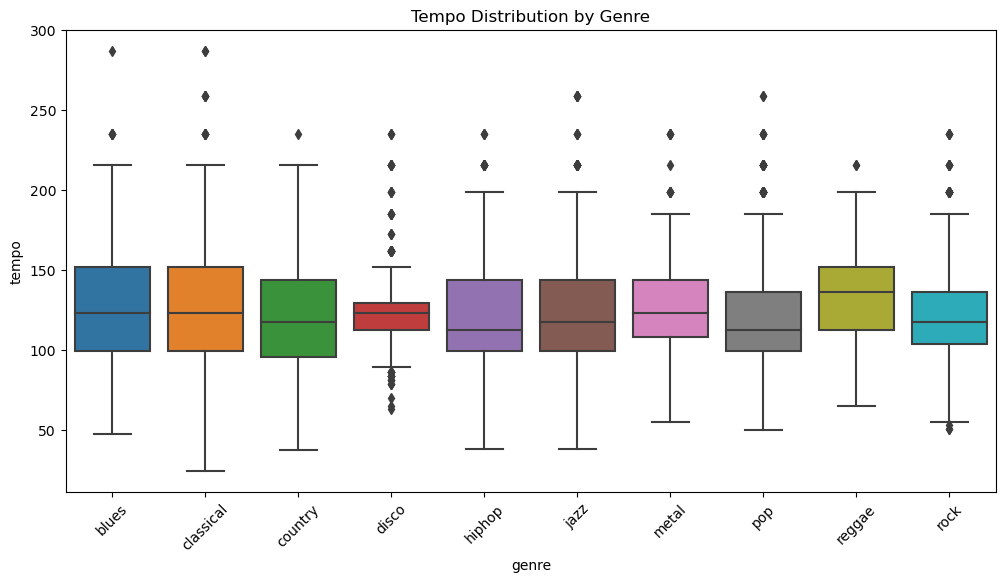

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
sns.boxplot(x='genre', y='tempo', data=df)
plt.title('Tempo Distribution by Genre')
plt.xticks(rotation=45)
plt.show()

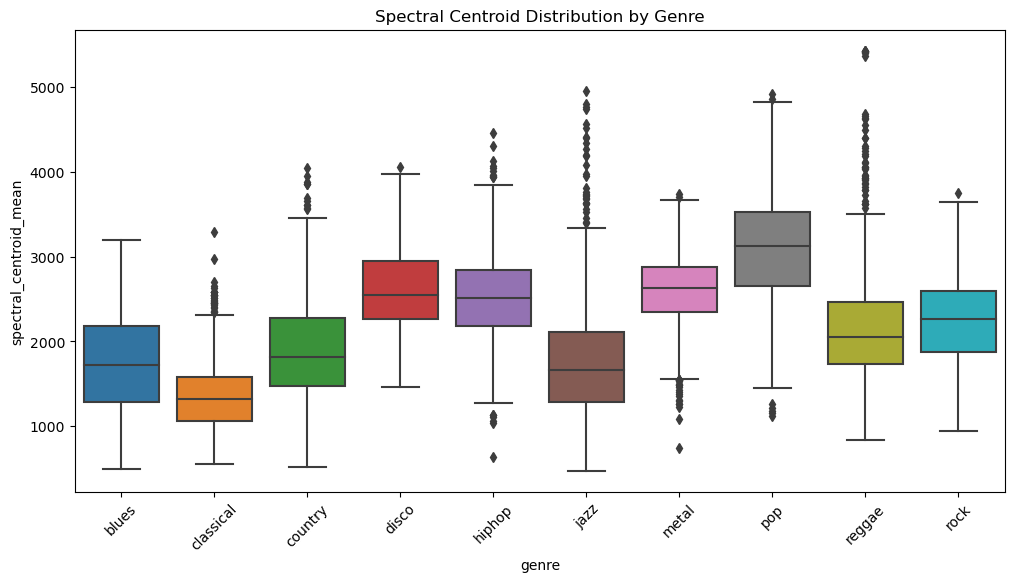

In [19]:
plt.figure(figsize=(12, 6))
sns.boxplot(x='genre', y='spectral_centroid_mean', data=df)
plt.title('Spectral Centroid Distribution by Genre')
plt.xticks(rotation=45)
plt.show()

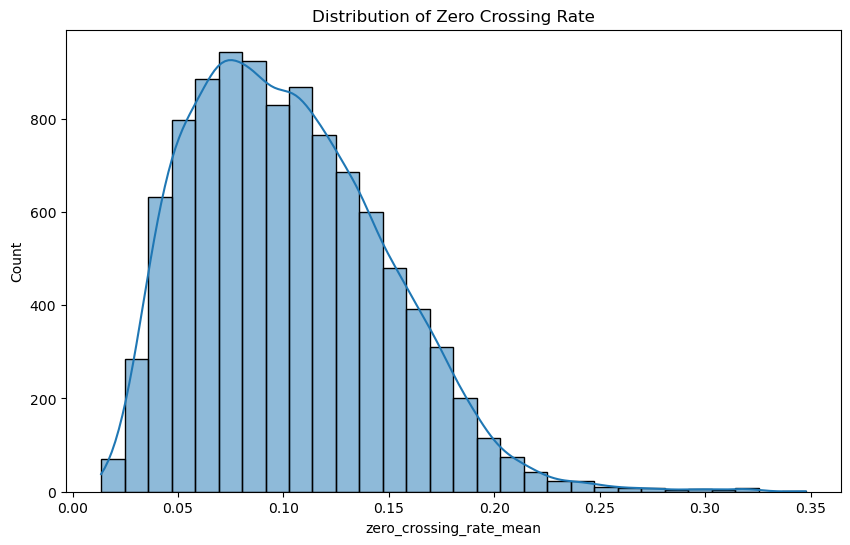

In [20]:
plt.figure(figsize=(10, 6))
sns.histplot(df['zero_crossing_rate_mean'], bins=30, kde=True)
plt.title('Distribution of Zero Crossing Rate')
plt.show()

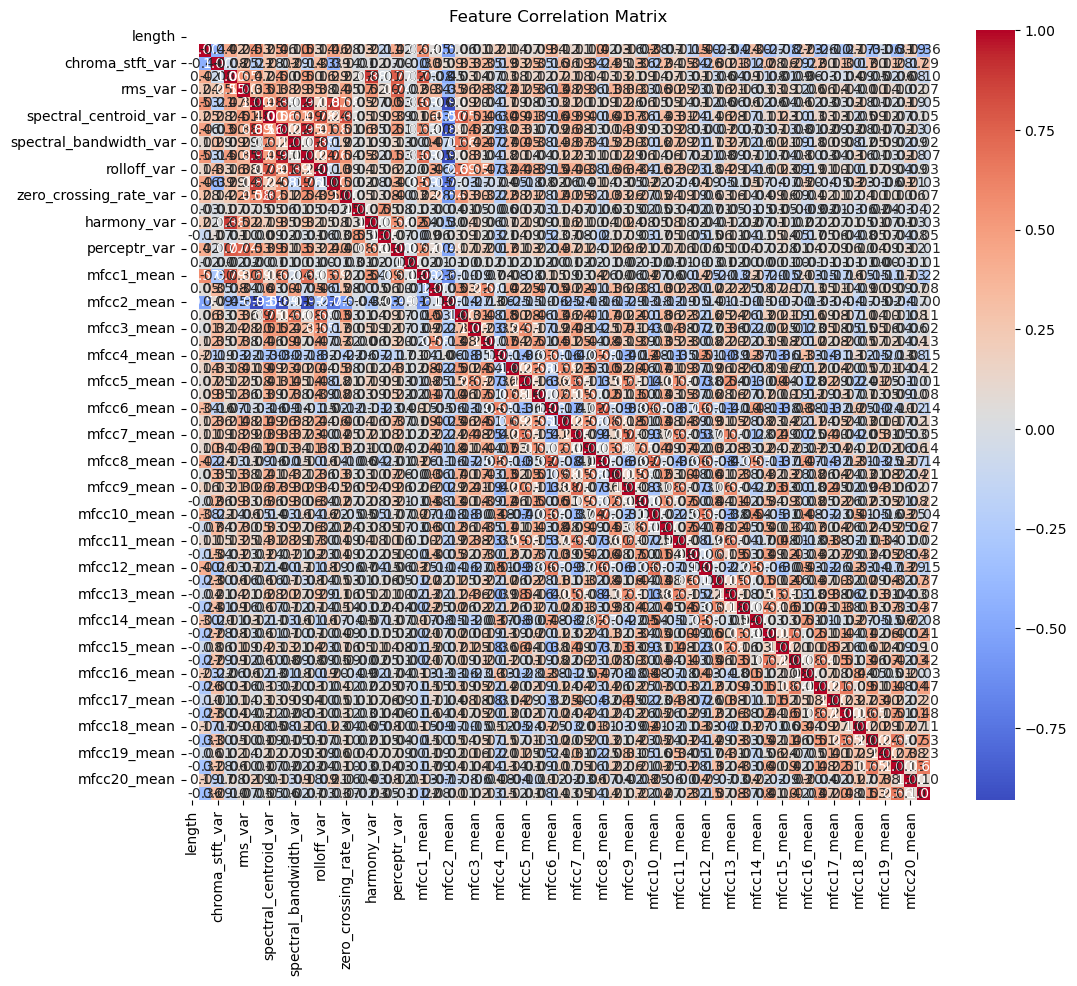

In [21]:
# Compute the correlation matrix
correlation_matrix = df.drop(columns=['filename', 'genre']).corr()

# Plot the correlation heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Matrix')
plt.show()

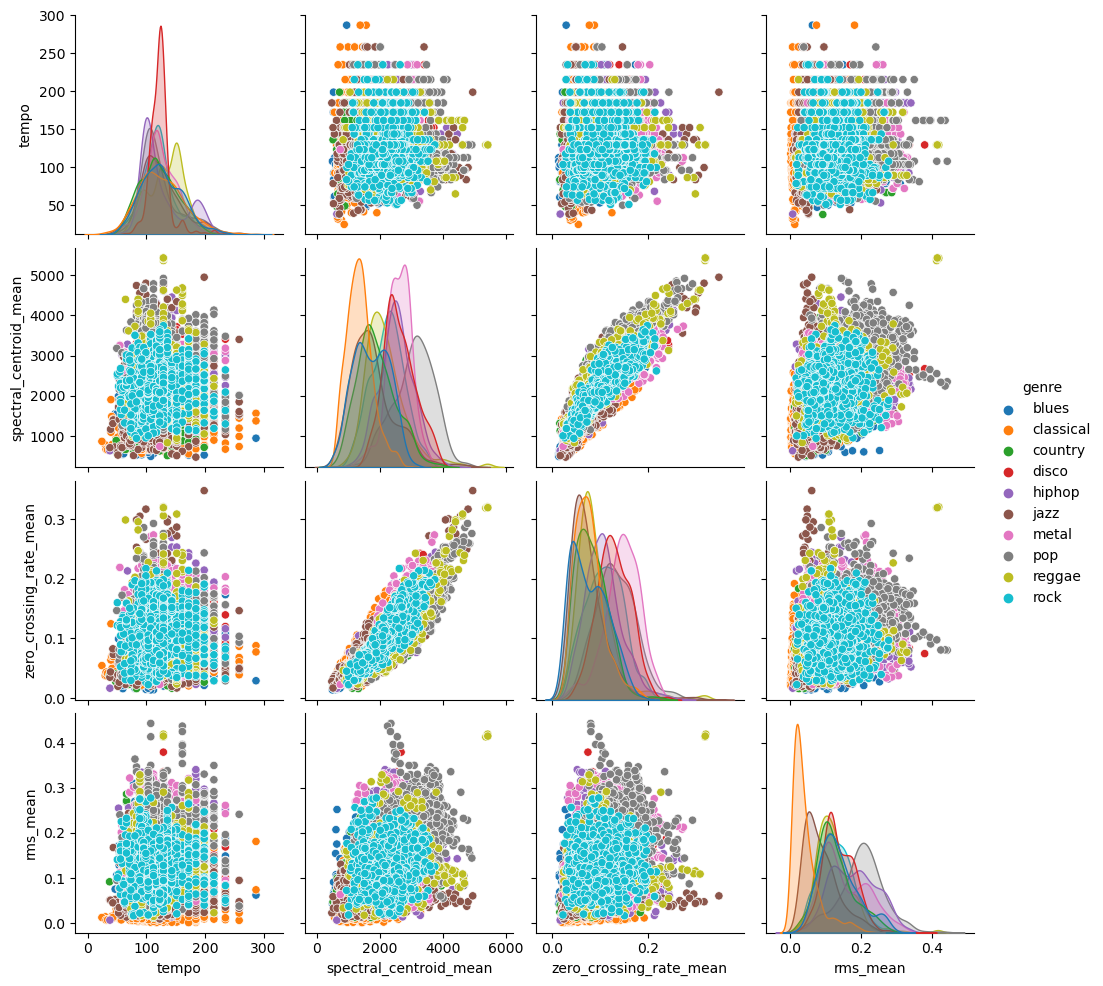

In [22]:
# Select a few features for pairplot
selected_features = ['tempo', 'spectral_centroid_mean', 'zero_crossing_rate_mean', 'rms_mean', 'genre']
sns.pairplot(df[selected_features], hue='genre', diag_kind='kde')
plt.show()

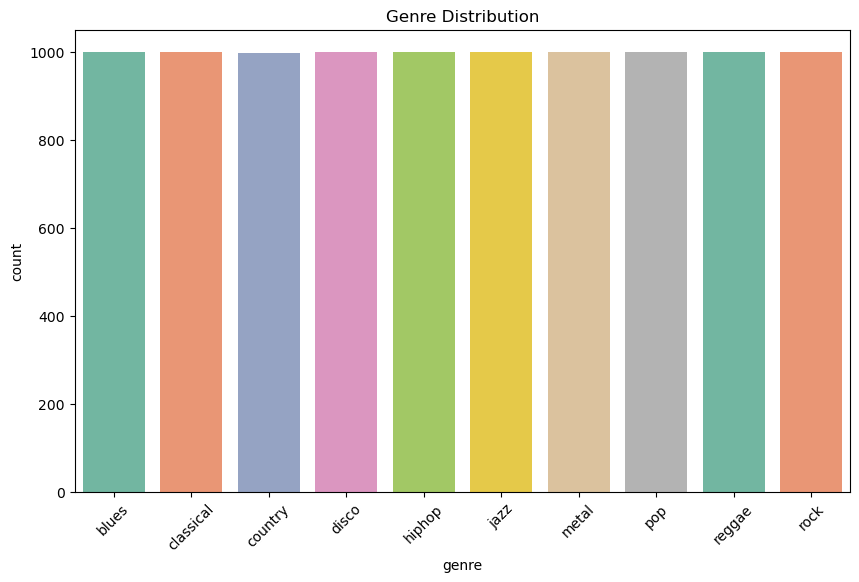

In [23]:
plt.figure(figsize=(10, 6))
sns.countplot(x='genre', data=df, palette='Set2')
plt.title('Genre Distribution')
plt.xticks(rotation=45)
plt.show()

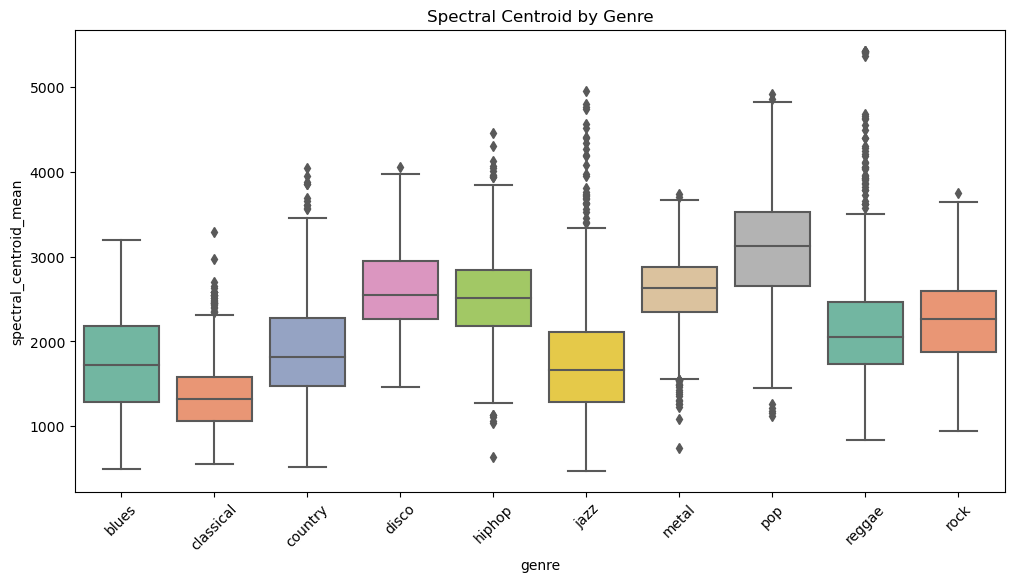

In [24]:
plt.figure(figsize=(12, 6))
sns.boxplot(x='genre', y='spectral_centroid_mean', data=df, palette='Set2')
plt.title('Spectral Centroid by Genre')
plt.xticks(rotation=45)
plt.show()

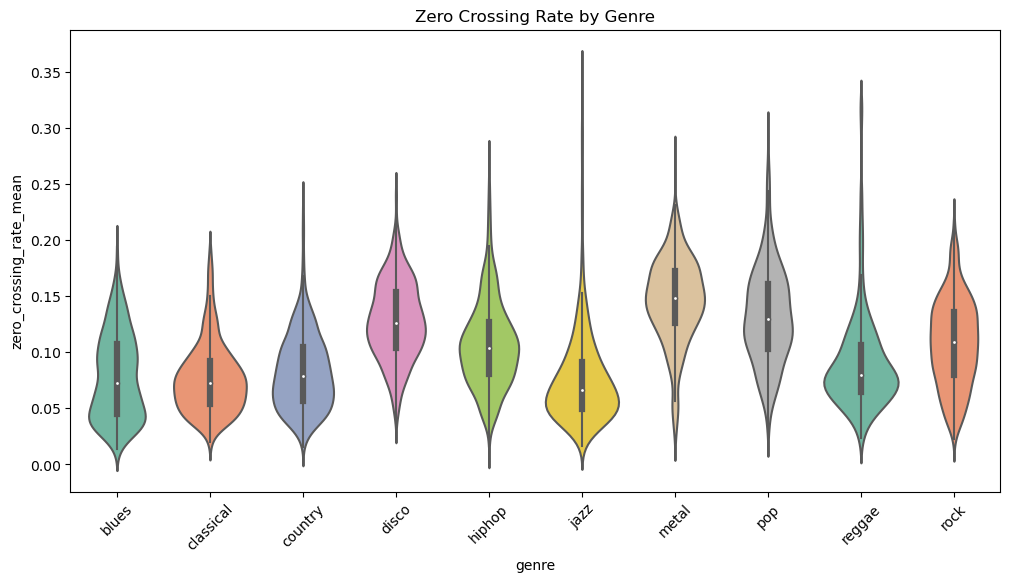

In [25]:
plt.figure(figsize=(12, 6))
sns.violinplot(x='genre', y='zero_crossing_rate_mean', data=df, palette='Set2')
plt.title('Zero Crossing Rate by Genre')
plt.xticks(rotation=45)
plt.show()

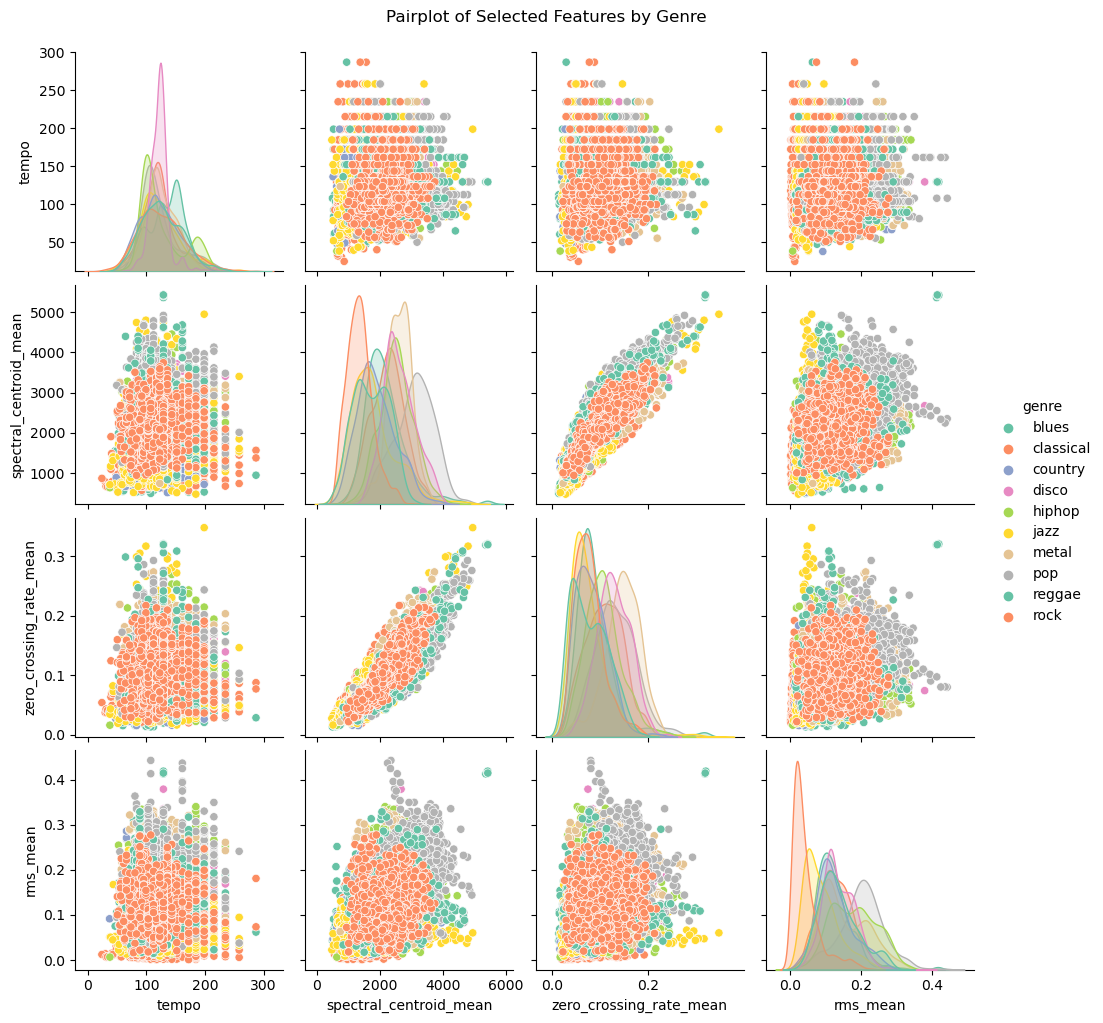

In [26]:
# Select a few features for pairplot
selected_features = ['tempo', 'spectral_centroid_mean', 'zero_crossing_rate_mean', 'rms_mean', 'genre']
sns.pairplot(df[selected_features], hue='genre', palette='Set2')
plt.suptitle('Pairplot of Selected Features by Genre', y=1.02)
plt.show()

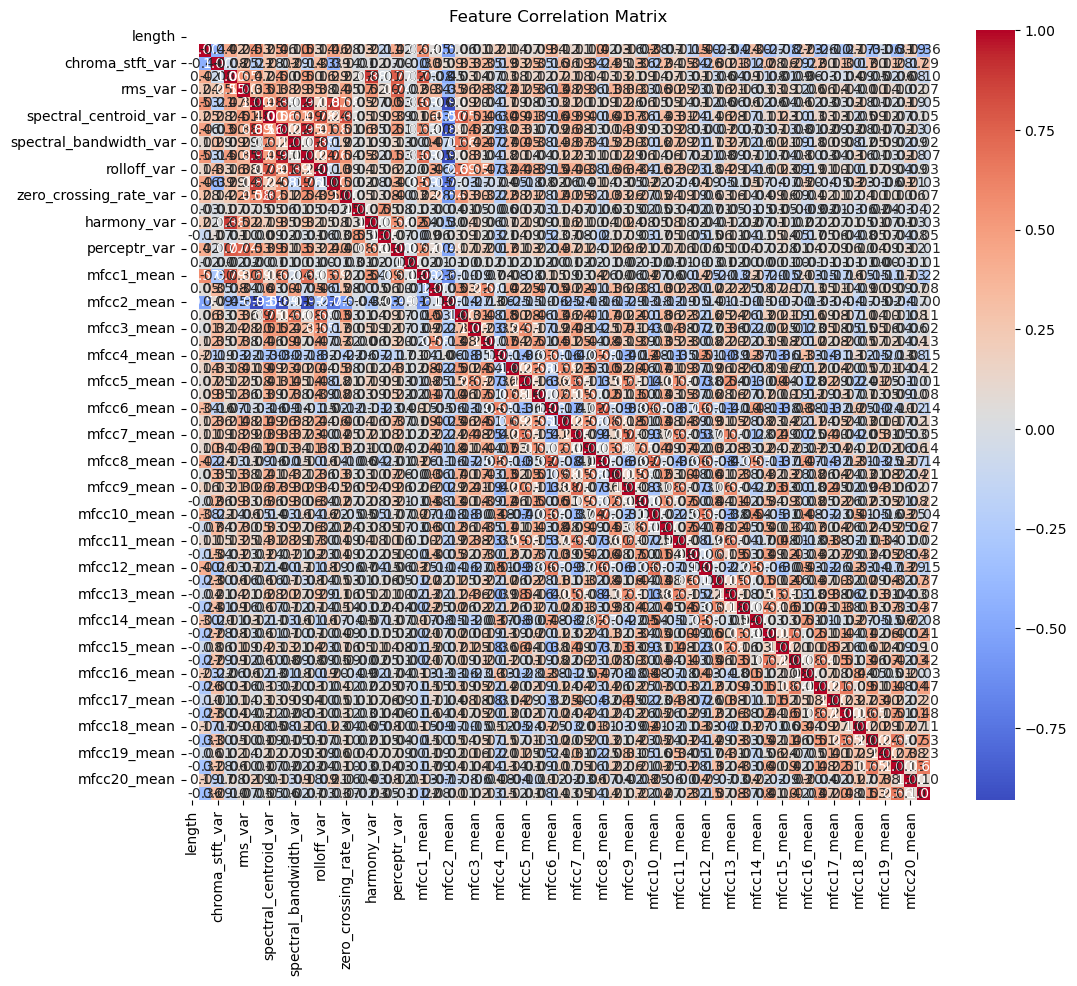

In [27]:
# Compute correlation matrix
correlation_matrix = df.drop(columns=['genre']).corr()

# Plot correlation heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Matrix')
plt.show()

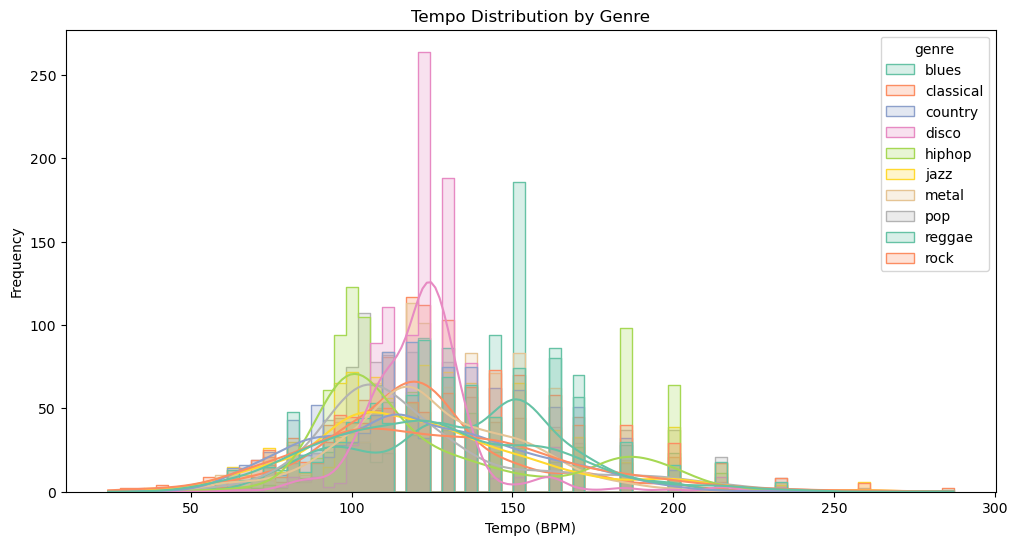

In [28]:
plt.figure(figsize=(12, 6))
sns.histplot(data=df, x='tempo', hue='genre', kde=True, palette='Set2', element='step')
plt.title('Tempo Distribution by Genre')
plt.xlabel('Tempo (BPM)')
plt.ylabel('Frequency')
plt.show()